## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

In [69]:
pip install fastparquet


Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [70]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

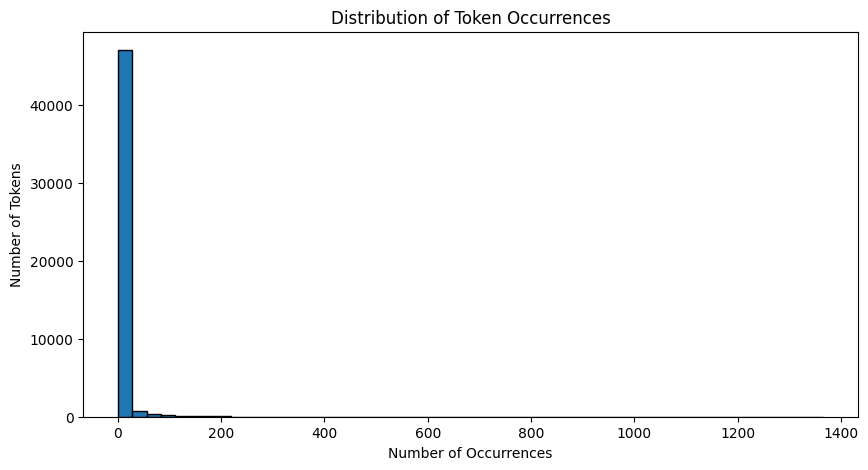

In [71]:

occurrences = list(token_count.values())

plt.figure(figsize=(10, 5))
plt.hist(occurrences, bins=50, edgecolor='black')

plt.title('Distribution of Token Occurrences')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.show()

# Most tokens occur only a few times, while relatively few occur very often.
# The distribution is right-skewed, with a long tail toward higher occurrence counts.
#This shows certain words are used very frequently, while many others are used rarely.

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [72]:
%pip install scikit-learn 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [73]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.decomposition import PCA

data = pd.read_parquet("data/Phishing_clean.parquet")

print(data.shape)
print(data.head())
print(data.columns)

x = data.drop(columns=["Email Type"])
y = data["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
print("Train R^2:", train_r2)
print("Test R^2:", test_r2)

coefficients = pd.Series(model.coef_, index=x.columns)
coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index)
print('this is the coefficients:', coefficients)
#the words with the largest coefficients are the most important for predicting the email type.
#The words with the smallest coefficients are the least important.



(18634, 2712)
   Email Type  new  date  get  please  enron  like  2002  would  one  ...  \
0           0    0     0    0       0      0     0     0      0    0  ...   
1           0    0     0    0       0      0     0     0      0    0  ...   
2           0    1     0    0       0      0     0     0      0    0  ...   
3           1    0     0    0       0      0     0     0      0    1  ...   
4           1    0     0    0       0      0     0     0      0    0  ...   

   ï¿½ï¿½  safety  yap  ypil  maintain  procedures  tip  elizabeth  \
0       0       0    0     0         0           0    0          0   
1       0       0    0     0         0           0    0          0   
2       0       0    0     0         0           0    0          0   
3       0       0    0     0         0           0    0          0   
4       0       0    0     0         0           0    0          0   

   leadership  italian  
0           0        0  
1           0        0  
2           0        0  
3 

/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: Runti

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

In [74]:
X = df.drop(columns=["Email Type"])
y = df["Email Type"]

pca2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

print("Explained variance ratio:", pca2.explained_variance_ratio_)
print("Total variance explained:", pca2.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca_2[:, 0],
    y=X_pca_2[:, 1],
    hue=y,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails by Email Type")
plt.legend(title="Email Type")
plt.show()

#in the PCA we see that the two principal components do not separate the email types very well.
#This suggests that the linear regression model may not be able to accurately predict the email type based on the features in the dataset.


/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/ara/Library

AttributeError: 'PCA' object has no attribute 'explained_variance_ratio_'

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [ ]:
pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Training shape after PCA:", X_train_pca.shape)
print("Testing shape after PCA:", X_test_pca.shape)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

y_train_pca_pred = pca_model.predict(X_train_pca)
y_test_pca_pred = pca_model.predict(X_test_pca)

pca_train_r2 = r2_score(y_train, y_train_pca_pred)
pca_test_r2 = r2_score(y_test, y_test_pca_pred)

print("PCA training R-squared:", pca_train_r2)
print("PCA testing R-squared:", pca_test_r2)

comparison = pd.DataFrame({
    "Model": [
        "Original features",
        "PCA with 2,610 components"
    ],
    "Training R-squared": [
        train_r2,
        pca_train_r2
    ],
    "Testing R-squared": [
        test_r2,
        pca_test_r2
    ]
})

print(comparison)

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

In [ ]:
#the advantages of using the PCA model are that you can reduce the size of the dataset to sets of principal components.
#Moreover, this can help reduce the the risks of overfitting, particularly when the number of features is large relative to the number of observations.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Araceli Soto

**Date:** 10/21/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
occurrences = list(token_count.values())

plt.figure(figsize=(10, 5))
plt.hist(occurrences, bins=50, edgecolor='black')

plt.title('Distribution of Token Occurrences')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.show()

# Most tokens occur only a few times, while relatively few occur very often.
# The distribution is right-skewed, with a long tail toward higher occurrence counts.
#This shows certain words are used very frequently, while many others are used rarely.
%pip install scikit-learn 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.decomposition import PCA

data = pd.read_parquet("data/Phishing_clean.parquet")

print(data.shape)
print(data.head())
print(data.columns)

x = data.drop(columns=["Email Type"])
y = data["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
print("Train R^2:", train_r2)
print("Test R^2:", test_r2)

coefficients = pd.Series(model.coef_, index=x.columns)
coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index)
print('this is the coefficients:', coefficients)
#the words with the largest coefficients are the most important for predicting the email type.
#The words with the smallest coefficients are the least important.
X = df.drop(columns=["Email Type"])
y = df["Email Type"]

pca2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

print("Explained variance ratio:", pca2.explained_variance_ratio_)
print("Total variance explained:", pca2.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca_2[:, 0],
    y=X_pca_2[:, 1],
    hue=y,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails by Email Type")
plt.legend(title="Email Type")
plt.show()

#in the PCA we see that the two principal components do not separate the email types very well.
#This suggests that the linear regression model may not be able to accurately predict the email type based on the features in the dataset.
pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Training shape after PCA:", X_train_pca.shape)
print("Testing shape after PCA:", X_test_pca.shape)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

y_train_pca_pred = pca_model.predict(X_train_pca)
y_test_pca_pred = pca_model.predict(X_test_pca)

pca_train_r2 = r2_score(y_train, y_train_pca_pred)
pca_test_r2 = r2_score(y_test, y_test_pca_pred)

print("PCA training R-squared:", pca_train_r2)
print("PCA testing R-squared:", pca_test_r2)

comparison = pd.DataFrame({
    "Model": [
        "Original features",
        "PCA with 2,610 components"
    ],
    "Training R-squared": [
        train_r2,
        pca_train_r2
    ],
    "Testing R-squared": [
        test_r2,
        pca_test_r2
    ]
})

print(comparison)

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [49607f4bf18ea907c8bb9fee83d3e20a18741ab6]
- **AI tool and model used:** [GPT-6 Sol]

### *Prompts used

1. [how can I improve this code?]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. plt is used before it is imported, Put all imports at the top of the notebook
2. You import several libraries more than once	Keep each import only once.
3. %pip install scikit-learn is in the middle of your code	Run it in a separate cell only if scikit-learn is not installed.
4. You use df in Question 3, but your DataFrame is called data	Use data consistently.
5. You create pca2 but use pca_2	Use pca2 consistently.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | ACCEPT / modify / reject | It will be helpful to to move the imports to the top so my codes is more organized |
| 2 | ACCEPT / modify / reject | I try to import things more than once because I feel like I dont have it written down but it good to be more organized to where i put imports to have a clearer data structure |
| 3 | accept / modify / REJECT | It still runs so I wont be changing it so i dont loose track of stuff. |
| 4 | ACCEPT / modify / reject | I stopped working on parts of assignments separetly and tend to loose track of names on accidents so I'll try to be better with that |
| 5 | ACCEPT / modify / reject | Same thing as the last thing |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

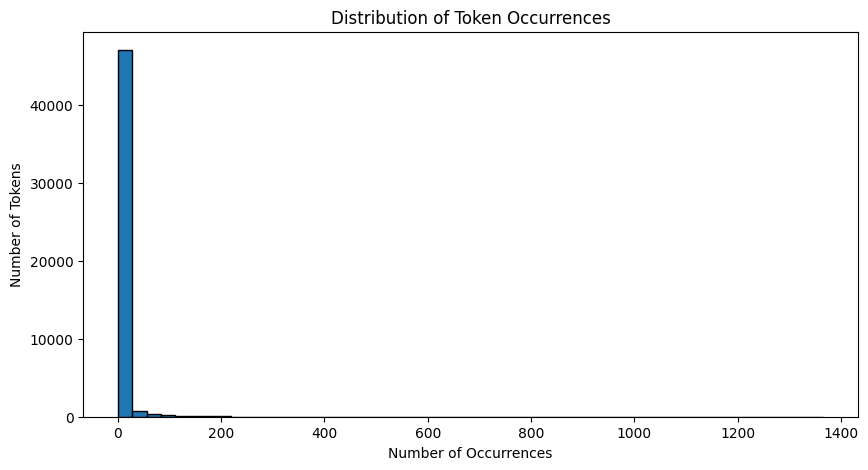

(18634, 2712)
   Email Type  new  date  get  please  enron  like  2002  would  one  ...  \
0           0    0     0    0       0      0     0     0      0    0  ...   
1           0    0     0    0       0      0     0     0      0    0  ...   
2           0    1     0    0       0      0     0     0      0    0  ...   
3           1    0     0    0       0      0     0     0      0    1  ...   
4           1    0     0    0       0      0     0     0      0    0  ...   

   ï¿½ï¿½  safety  yap  ypil  maintain  procedures  tip  elizabeth  \
0       0       0    0     0         0           0    0          0   
1       0       0    0     0         0           0    0          0   
2       0       0    0     0         0           0    0          0   
3       0       0    0     0         0           0    0          0   
4       0       0    0     0         0           0    0          0   

   leadership  italian  
0           0        0  
1           0        0  
2           0        0  
3 

/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: Runti

Train R^2: 0.7670143724934355
Test R^2: 0.665871843884793
This is the coefficients: intervention        -1.259257e+00
localized            8.243505e-01
thermal              7.470065e-01
crawler              6.961667e-01
background-image:   -6.229094e-01
                         ...     
2005                -5.551115e-17
09,                 -4.163336e-17
7.3                  4.163336e-17
301                  6.938894e-18
750                  0.000000e+00
Length: 2711, dtype: float64


/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/ara/Library

Explained variance ratio: [0.01113089 0.00861177]
Total variance explained: 0.01974266783364772


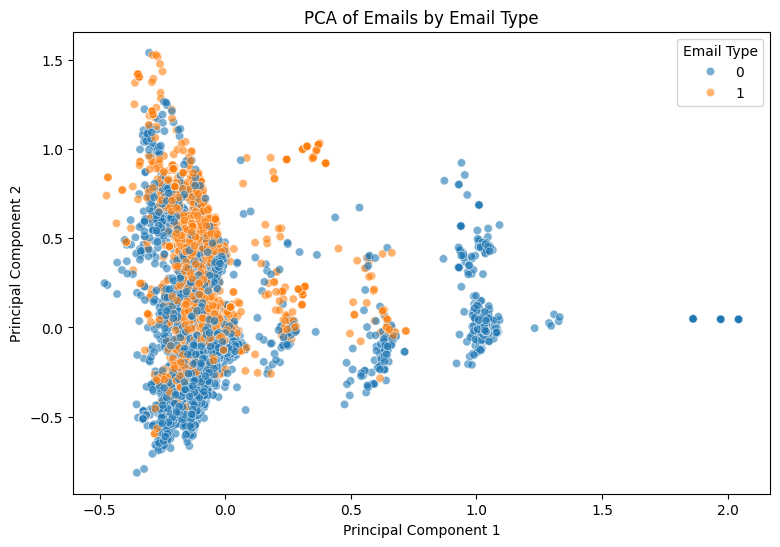

/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:155: RuntimeWarning: divide by zero encountered in matmul
  X_transformed -= xp.reshape(self.mean_, (1, -1)) @ self.components_.T
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:155: RuntimeWarning: overflow encountered in matmul
  X_transformed -= xp.reshape(self.mean_, (1, -1)) @ self.components_.T
/Users/ara/Library/Python/

Training shape after PCA: (14907, 2610)
Testing shape after PCA: (3727, 2610)
PCA training R-squared: 0.7662326827745853
PCA testing R-squared: 0.6683390643101157
                       Model  Training R-squared  Testing R-squared
0          Original features            0.767014           0.665872
1  PCA with 2,610 components            0.766233           0.668339


/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/ara/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: Runti

In [75]:
# Your Phase 2 solution to the problem goes here.
import pickle
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.decomposition import PCA

with open("data/all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()
occurrences = list(token_count.values())

plt.figure(figsize=(10, 5))
plt.hist(occurrences, bins=50, edgecolor="black")

plt.title("Distribution of Token Occurrences")
plt.xlabel("Number of Occurrences")
plt.ylabel("Number of Tokens")
plt.show()

# Most tokens occur only a few times, while relatively few occur very often.
# The distribution is right-skewed, with a long tail toward higher occurrence counts.
# This shows certain words are used very frequently, while many others are used rarely.


data = pd.read_parquet("data/Phishing_clean.parquet")

print(data.shape)
print(data.head())
print(data.columns)

X = data.drop(columns=["Email Type"])
y = data["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Train R^2:", train_r2)
print("Test R^2:", test_r2)

coefficients = pd.Series(model.coef_, index=X.columns)
coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index
)

print("This is the coefficients:", coefficients)

# The words with the largest absolute coefficients have the strongest
# fitted relationships with the predicted email type.
# The words with smaller absolute coefficients have weaker fitted relationships.


pca2 = PCA(n_components=2)
X_pca_2 = pca2.fit_transform(X)

print("Explained variance ratio:", pca2.explained_variance_ratio_)
print("Total variance explained:", pca2.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca_2[:, 0],
    y=X_pca_2[:, 1],
    hue=y,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails by Email Type")
plt.legend(title="Email Type")
plt.show()

# In the PCA plot, the two principal components do not separate the email
# types very well. However, this does not necessarily mean that the original
# features cannot predict email type accurately.


pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Training shape after PCA:", X_train_pca.shape)
print("Testing shape after PCA:", X_test_pca.shape)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

y_train_pca_pred = pca_model.predict(X_train_pca)
y_test_pca_pred = pca_model.predict(X_test_pca)

pca_train_r2 = r2_score(y_train, y_train_pca_pred)
pca_test_r2 = r2_score(y_test, y_test_pca_pred)

print("PCA training R-squared:", pca_train_r2)
print("PCA testing R-squared:", pca_test_r2)

comparison = pd.DataFrame({
    "Model": [
        "Original features",
        "PCA with 2,610 components"
    ],
    "Training R-squared": [
        train_r2,
        pca_train_r2
    ],
    "Testing R-squared": [
        test_r2,
        pca_test_r2
    ]
})

print(comparison)

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

In [76]:
# I learned  that moving imports to the top of the notebook is a good practice for better organization and readability. 
# It also helps to avoid potential issues with module dependencies and ensures that all necessary libraries are available before executing any code cells.
# I realized that I sometimes import things more than once because I forget where I already wrote them, so I want to be better about organizing my code.
#Moreover I decided to keep printing all the coefficients because my code still runs, and I do not want to change too much and lose track of what I am doing.
#Overall, I learned that even when my code runs, I can still improve how I organize it and make it easier to understand.